# DDPM 与 DDIM：从公式到可运行实现的引导式学习

> 目标：在一个小型二维数据集上亲手实现扩散模型的关键部件，理解 **DDPM 的随机反向采样** 与 **DDIM 的确定性/加速采样**。
>
> 使用方式：先阅读每节推导，再完成标记为 **✍️ 请你填写** 的 TODO；最后运行自检与训练/采样实验。

## 学习路线

1. 构造前向马尔可夫扩散 $q(x_t\mid x_{t-1})$。
2. 由闭式公式直接从 $x_0$ 采样任意时刻的 $x_t$。
3. 训练网络预测噪声 $\epsilon$，并理解为何 MSE 足够。
4. 用 DDPM 反向更新式逐步生成样本。
5. 用 DDIM 的非马尔可夫路径、时间步跳跃与 $\eta$ 控制随机性。

建议：不要直接看答案区，先自己推导和实现。


In [1]:
import math
import random
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(7)
np.random.seed(7)
random.seed(7)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)


device: cuda


## 1. 前向扩散：逐步加入高斯噪声

DDPM 定义固定的前向过程：

$$q(x_t\mid x_{t-1})=\mathcal N\left(x_t;\sqrt{1-\beta_t}x_{t-1},\beta_t I\right).$$

记 $\alpha_t=1-\beta_t$，$\bar\alpha_t=\prod_{s=1}^{t}\alpha_s$。将多步高斯过程合并后：

$$q(x_t\mid x_0)=\mathcal N\left(x_t;\sqrt{\bar\alpha_t}x_0,(1-\bar\alpha_t)I\right),$$

因此可用一次采样得到任意 $t$ 的噪声样本：

$$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,\qquad\epsilon\sim\mathcal N(0,I).$$

### 思考题
- 为什么当 $\bar\alpha_t\to 0$ 时，$x_t$ 几乎不含 $x_0$ 信息？
- 这条闭式公式为什么对训练效率至关重要？


Font 'default' does not have a glyph for '\u6570' [U+6570], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u636e' [U+636e], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u5206' [U+5206], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u5e03' [U+5e03], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u6570' [U+6570], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u636e' [U+636e], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u5206' [U+5206], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u5e03' [U+5e03], substituting with a dummy symbol.


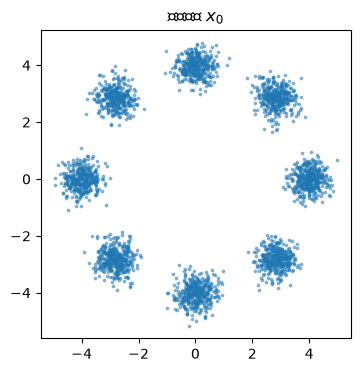

In [2]:
def sample_8gaussians(n, radius=4.0, std=0.35):
    angles = torch.randint(0, 8, (n,)) * (2 * math.pi / 8)
    centers = torch.stack([radius * torch.cos(angles), radius * torch.sin(angles)], dim=1)
    return centers + std * torch.randn(n, 2)

x0 = sample_8gaussians(3000)
plt.figure(figsize=(4, 4))
plt.scatter(x0[:, 0], x0[:, 1], s=3, alpha=.45)
plt.axis('equal'); plt.title('数据分布 $x_0$'); plt.show()


In [3]:
# 真实图像常用 T=1000；本教程用较小 T 以便快速实验。
T = 200
betas = torch.linspace(1e-4, 2e-2, T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

def extract(a, t, x_shape):
    """从长度 T 的向量按 batch 时间索引取值，并扩展到可广播形状。"""
    out = a.gather(0, t)
    return out.reshape(t.shape[0], *((1,) * (len(x_shape) - 1)))

def q_sample(x0, t, noise=None):
    """按照 q(x_t | x_0) 直接加噪。"""
    if noise is None:
        noise = torch.randn_like(x0)
    # ✍️ 请你填写：返回 sqrt(alpha_bar_t) * x0 + sqrt(1-alpha_bar_t) * noise
    # 提示：用 extract(alpha_bars, t, x0.shape) 取得每个样本的 alpha_bar_t。
    alpha_bar_t = extract(alpha_bars, t, x0.shape)
    return torch.sqrt(alpha_bar_t) * x0 + torch.sqrt(1 - alpha_bar_t) * noise
    raise NotImplementedError('完成 q_sample 后再运行本节。')


### 自检 1：前向闭式公式

完成 `q_sample` 后运行。观察：$t$ 越大，8 个簇的结构越模糊；末期近似各向同性标准高斯。


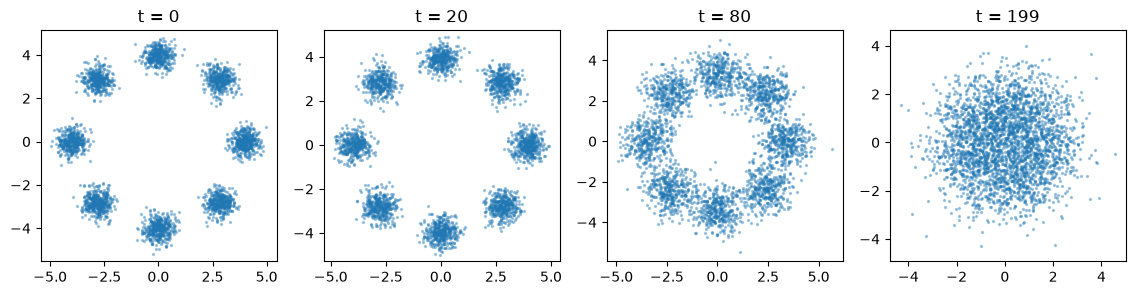

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, step in zip(axes, [0, 20, 80, 199]):
    xt = q_sample(x0.to(device), torch.full((len(x0),), step, device=device, dtype=torch.long)).cpu()
    ax.scatter(xt[:, 0], xt[:, 1], s=2, alpha=.35)
    ax.set_title(f't = {step}'); ax.axis('equal')
plt.show()


## 2. 为什么预测噪声？

反向真实后验是可解析的：

$$q(x_{t-1}\mid x_t,x_0)=\mathcal N(\tilde\mu_t(x_t,x_0),\tilde\beta_t I),$$

其中

$$\tilde\mu_t=\frac{\sqrt{\bar\alpha_{t-1}}\beta_t}{1-\bar\alpha_t}x_0+\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t.$$

生成时未知 $x_0$。根据重参数化式，可由预测噪声恢复：

$$\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}}.$$

DDPM 的简化训练目标为：

$$\mathcal L_{simple}=\mathbb E_{x_0,\epsilon,t}\left[\lVert\epsilon-\epsilon_\theta(x_t,t)\rVert_2^2\right].$$

关键点：网络不是“凭空去噪”，而是在不同噪声等级下估计被注入的 $\epsilon$。


In [5]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / max(half - 1, 1))
        args = t.float()[:, None] * freqs[None, :]
        return torch.cat([args.sin(), args.cos()], dim=-1)

class NoisePredictor(nn.Module):
    """二维输入的 MLP 噪声预测器；图像任务中通常替换成 U-Net。"""
    def __init__(self, hidden=128, time_dim=32):
        super().__init__()
        self.time = nn.Sequential(SinusoidalTimeEmbedding(time_dim), nn.Linear(time_dim, hidden), nn.SiLU())
        self.net = nn.Sequential(
            nn.Linear(2 + hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, 2))

    def forward(self, xt, t):
        return self.net(torch.cat([xt, self.time(t)], dim=-1))

model = NoisePredictor().to(device)
print('parameters:', sum(p.numel() for p in model.parameters()))


parameters: 37762


In [6]:
def diffusion_loss(model, x0):
    """随机采样 t 与 eps，返回 DDPM 简化目标。"""
    t = torch.randint(0, T, (x0.shape[0],), device=x0.device)
    noise = torch.randn_like(x0)
    xt = q_sample(x0, t, noise)
    pred_noise = model(xt, t)
    # ✍️ 请你填写：返回预测噪声与真实噪声的均方误差。
    # return ...
    return torch.mean(torch.square(pred_noise - noise))
    raise NotImplementedError('完成 diffusion_loss。')


step= 500, loss=0.5939
step=1000, loss=0.5921
step=1500, loss=0.5853
step=2000, loss=0.5818
step=2500, loss=0.5887
step=3000, loss=0.5827
step=3500, loss=0.5960
step=4000, loss=0.5866
step=4500, loss=0.5924
step=5000, loss=0.5844
step=5500, loss=0.5856
step=6000, loss=0.5856
step=6500, loss=0.5811
step=7000, loss=0.5863
step=7500, loss=0.5862
step=8000, loss=0.5807
step=8500, loss=0.5868
step=9000, loss=0.5830
step=9500, loss=0.5796
step=10000, loss=0.5857
step=10500, loss=0.5845
step=11000, loss=0.5813
step=11500, loss=0.5823
step=12000, loss=0.5810
step=12500, loss=0.5781
step=13000, loss=0.5807
step=13500, loss=0.5840
step=14000, loss=0.5835
step=14500, loss=0.5893
step=15000, loss=0.5833
step=15500, loss=0.5749
step=16000, loss=0.5784
step=16500, loss=0.5851
step=17000, loss=0.5776
step=17500, loss=0.5888
step=18000, loss=0.5816
step=18500, loss=0.5800
step=19000, loss=0.5838
step=19500, loss=0.5803
step=20000, loss=0.5813
step=20500, loss=0.5852
step=21000, loss=0.5869
step=21500,

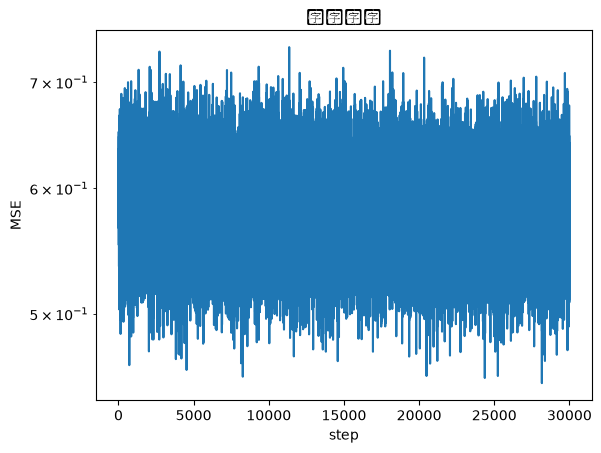

In [8]:
def train(model, steps=30000, batch_size=512, lr=2e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    model.train()
    for step in range(steps):
        batch = sample_8gaussians(batch_size).to(device)
        loss = diffusion_loss(model, batch)
        opt.zero_grad(); loss.backward(); opt.step()
        history.append(loss.item())
        if (step + 1) % 500 == 0:
            print(f'step={step+1:4d}, loss={np.mean(history[-100:]):.4f}')
    return history

history = train(model)
plt.plot(history); plt.yscale('log'); plt.title('训练损失'); plt.xlabel('step'); plt.ylabel('MSE'); plt.show()


## 3. DDPM 采样：每一步保留随机性

用 $\epsilon_\theta$ 参数化均值，Ho et al. 的采样更新式：

$$x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t,t)\right)+\sigma_t z,$$

其中 $z\sim\mathcal N(0,I)$（在 $t=0$ 时令 $z=0$），并通常取

$$\sigma_t^2=\tilde\beta_t=\beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}.$$

- 平均项：依据网络噪声估计向更干净的数据空间移动。
- 随机项：匹配反向条件分布的方差。
- 标准 DDPM 通常需走完训练时的全部 $T$ 步。


In [9]:
@torch.no_grad()
def ddpm_sample(model, n_samples=2000):
    model.eval()
    x = torch.randn(n_samples, 2, device=device)
    alpha_bars_prev = F.pad(alpha_bars[:-1], (1, 0), value=1.0)

    for step in reversed(range(T)):
        t = torch.full((n_samples,), step, device=device, dtype=torch.long)
        eps_theta = model(x, t)
        alpha_t = alphas[step]
        alpha_bar_t = alpha_bars[step]
        alpha_bar_prev = alpha_bars_prev[step]
        beta_t = betas[step]

        # ✍️ 请你填写：实现上方 DDPM 更新式的 mean 与随机项。
        mean = (x - (1 - alpha_t) * eps_theta / (math.sqrt(1 - alpha_bar_t))) / math.sqrt(alpha_t)
        posterior_var = beta_t * (1 - alpha_bar_prev) / (1 - alpha_bar_t)
        noise = torch.randn_like(x) if step > 0 else torch.zeros_like(x)
        x = mean + torch.sqrt(posterior_var) * noise
        # raise NotImplementedError('完成 ddpm_sample 的更新式。')
    return x.cpu()


## 4. DDIM：同一训练目标，另一条反向轨迹

DDIM 不需要重新训练网络。它构造一族拥有相同边缘分布 $q(x_t\mid x_0)$ 的非马尔可夫过程，并使用预测的 $\hat{x}_0$ 更新：

$$x_{t'}=\sqrt{\bar\alpha_{t'}}\hat{x}_0+\sqrt{1-\bar\alpha_{t'}-\sigma_t^2}\epsilon_\theta(x_t,t)+\sigma_t z,$$

其中 $t'<t$，并且

$$\sigma_t=\eta\sqrt{\frac{1-\bar\alpha_{t'}}{1-\bar\alpha_t}}\sqrt{1-\frac{\bar\alpha_t}{\bar\alpha_{t'}}}.$$

- $\eta=0$：完全确定性；同一初始噪声给出同一结果，适合 inversion/编辑思路。
- $\eta=1$：随机程度与 DDPM 风格接近。
- 只选择 $S\ll T$ 个时间点即可采样，因此可更快。

注意：DDIM 的“快”来自**跨时间步跳跃**，不是单步网络推理变快。


In [12]:
@torch.no_grad()
def ddim_sample(model, n_samples=2000, sample_steps=40, eta=0.0):
    assert 1 <= sample_steps <= T
    model.eval()
    x = torch.randn(n_samples, 2, device=device)
    times = torch.linspace(T - 1, 0, sample_steps, device=device).long().unique_consecutive()

    for i, step in enumerate(times):
        t = torch.full((n_samples,), int(step), device=device, dtype=torch.long)
        eps_theta = model(x, t)
        alpha_bar_t = alpha_bars[step]
        prev_step = times[i + 1] if i + 1 < len(times) else torch.tensor(-1, device=device)
        alpha_bar_prev = alpha_bars[prev_step] if prev_step >= 0 else torch.tensor(1.0, device=device)

        # ✍️ 请你填写：
        # 1) 根据 eps_theta 从 x 恢复 x0_pred；
        # 2) 写出 sigma（注意 eta）；
        # 3) 组合 direction + stochastic noise 得到新的 x。
        # 建议先实现 eta=0 的确定性版本，再加入随机项。
        x0_pred = (x - math.sqrt(1 - alpha_bar_t) * eps_theta) / math.sqrt(alpha_bar_t)
        sigma_t = eta * math.sqrt((1 - alpha_bar_prev) / (1 - alpha_bar_t)) * math.sqrt(1 - alpha_bar_t / alpha_bar_prev)
        noise = torch.rand_like(x) if eta > 0 and prev_step >= 0 else torch.zeros_like(x)
        x = math.sqrt(alpha_bar_prev) * x0_pred + math.sqrt(1 - alpha_bar_prev - sigma_t ** 2) * eps_theta + sigma_t * noise
        # raise NotImplementedError('完成 ddim_sample。')
    return x.cpu()


## 5. 实验与自我检验

完成两个采样器后，运行下面代码并回答：

1. DDPM-200 步与 DDIM-40 步的簇结构、离群点比例有何差异？
2. 固定 `torch.manual_seed`，DDIM 在 $\eta=0$ 时是否可复现？将 $\eta$ 改为 1 呢？
3. 将 `sample_steps` 改为 10、20、40、100，质量从何处开始显著下降？为什么？
4. 若网络直接预测 $x_0$ 或 v-prediction，公式中的哪些位置需要变化？


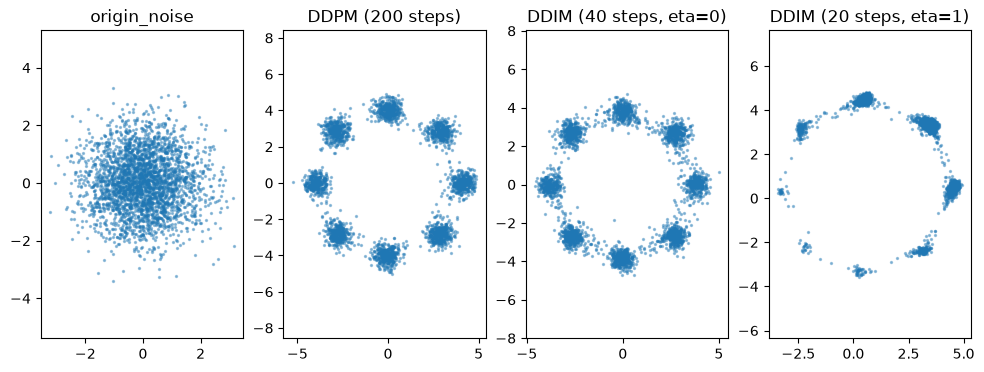

In [15]:
origin_noise = torch.randn(3000, 2, device="cpu")
samples_ddpm = ddpm_sample(model, 3000)
samples_ddim_40 = ddim_sample(model, 3000, sample_steps=40, eta=0.0)
samples_ddim_20_stochastic = ddim_sample(model, 3000, sample_steps=20, eta=1.0)

fig, axes = plt.subplots(1, 4, figsize=(12, 4))
for ax, samples, title in zip(
    axes,
    [origin_noise, samples_ddpm, samples_ddim_40, samples_ddim_20_stochastic],
    ['origin_noise', 'DDPM (200 steps)', 'DDIM (40 steps, eta=0)', 'DDIM (20 steps, eta=1)']):
    ax.scatter(samples[:, 0], samples[:, 1], s=2, alpha=.4)
    ax.set_title(title); ax.axis('equal')
plt.show()


## 6. 答案核对（建议完成后再看）

### `q_sample`
```python
a_bar = extract(alpha_bars, t, x0.shape)
return torch.sqrt(a_bar) * x0 + torch.sqrt(1 - a_bar) * noise
```

### `diffusion_loss`
```python
return F.mse_loss(pred_noise, noise)
```

### DDPM 的均值
```python
mean = (x - (1 - alpha_t) / torch.sqrt(1 - alpha_bar_t) * eps_theta) / torch.sqrt(alpha_t)
```

### DDIM 的核心参考实现
```python
x0_pred = (x - torch.sqrt(1 - alpha_bar_t) * eps_theta) / torch.sqrt(alpha_bar_t)
sigma = eta * torch.sqrt((1 - alpha_bar_prev) / (1 - alpha_bar_t)) * torch.sqrt(1 - alpha_bar_t / alpha_bar_prev)
direction = torch.sqrt(torch.clamp(1 - alpha_bar_prev - sigma**2, min=0.0)) * eps_theta
noise = torch.randn_like(x) if eta > 0 and prev_step >= 0 else torch.zeros_like(x)
x = torch.sqrt(alpha_bar_prev) * x0_pred + direction + sigma * noise
```

实践中建议对 $\hat x_0$ 做裁剪（图像通常在 $[-1,1]$），并注意 float32 的数值稳定性。


## 7. 延伸挑战

- 将二维 MLP 替换为 MNIST 上的 U-Net；输入为 $[B,C,H,W]$，时间嵌入注入残差块。
- 实现 classifier-free guidance：训练中随机置空条件，采样时组合条件/无条件噪声预测。
- 实现 DDIM inversion：从真实样本沿 $\eta=0$ 的确定性轨迹走向潜变量。
- 比较线性、余弦 beta 日程；绘制 $\bar\alpha_t$ 与信噪比 $\bar\alpha_t/(1-\bar\alpha_t)$。

如果你能不看答案推导并实现三个 TODO，就已掌握 DDPM/DDIM 最核心的计算图。
